
# Exposure time and number of layers columns for MER final catalogs

Copyright (c) Daniel Hernandez Lang, Martin Kuemmel 

This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.

Last modified: 2026-10-13

### Notebook summary

The Euclid satellite observes the sky in a specific observing sequence involving smaller and larger positional shifts between the individual exposures ([Scaramella et al 2022](https://www.aanda.org/articles/aa/abs/2022/06/aa41938-21/aa41938-21.html)). The imaging data produced by the OU-MER processing function as part of the Euclid SGS data reduction is positioned in a grid which is independent of the Euclid observations. Imaging data and objects catalogs are produced for the area covering a grid positions that is called tile (Kuemmel et al. 2026). Due to the dithering and the observing strategy the exposure time and the number of layers covering each position in a tile differ across a tile.

The data in the Euclid Data Release 1 contain the so called layer files, which store for the Euclid bands VIS, NIR-Y, NIR-J and NIR-H the position of all single epoch frames that cover a tile image. These files allow to compute the objects specific exposure time and the number of layers.

Provided as input the:
* one or several tiles to target
* a single band to target **or** all Euclid bands

the notebook computes the exposure timme and number of layers for each object in the final MER catalog of each tile and writes them into the columns of an extended object catalog to the output. The user can also opt to store the exposure time as a FITS image in the same coordinate system as the Eucid band images.

There are important limitations to consider:
* the position specific information is computed for the healpix indices covering the images, and the chosen healpix order sets the available resolution;
* the position specific information is based on the positioning of the single epoch frames and does not take into account defective pixels due to cosmics or persistence or similar;
* each object is provided the position specific information which corresponds to the healpix of the central objects position.

The next cell contains one of the two main classes. Resolves the area covered by an image into the healpix indices of a given order. Given the information provided in a layer file the exposure time for the indices is accumulated and the number of covering layers is recorded. The results are written in a FITS table.

**Just skip over the cell**

In [2]:
%matplotlib inline

import math
import time
import os.path

from shapely.geometry import Polygon
from shapely.geometry import Point

import numpy
import healpy
from astropy.io import fits
from astropy import wcs
from  astropy import units as u
import astropy.coordinates
from astropy.coordinates import SkyCoord

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from   mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
#from matplotlib.patches import Polygon.patches
from matplotlib import patches
from matplotlib import cm

PIHALF = math.pi/2.0
VIS_RESOLUTION = 0.1 # asec/pix

import warnings
warnings.filterwarnings("ignore")
plt.set_loglevel('WARNING')

class MER_LayerProcessor(object):
    """
    """
    def __init__(self, mosaic_image, order=13, logger=None):
        """
        """
        # store all input
        self._mosaic_image = mosaic_image
        self._order = order
        self._nside = healpy.order2nside(order)
        self._resolution = astropy.coordinates.Angle(healpy.nside2resol(self._nside, arcmin=False), unit=u.rad)
        self._overlap_calibs = []
        self._n_overlap_calibs = []
        self._logger = logger
        self._n_in =0
        self._n_skip =0
        # do the setup for the coverage map
        self._boundary_polygon, self._healpix_list, self._meridian_cross = self._setup(mosaic_image, self._nside)
        self._n_layers = numpy.zeros(len(self._healpix_list), dtype=numpy.int32)
        self._exptime = numpy.zeros(len(self._healpix_list), dtype=numpy.float32)
        self._info('')
        self._info('Number of indices: %i dtype: %s' % (len(self._healpix_list), self._healpix_list.dtype))
        self._info('Resolution %s' % str(self._resolution.to('arcsec')))
        if self._meridian_cross:
            self._info('Tile crossing the Meridian!')
        self._info('')
        self._info('')

    def _info(self, message):
        """General feedback method
        """
        # push to the logger if existing
        if self._logger is not None:
            self._logger.info('# %s' % message)
        else:
            # push to stdout
            print('# %s'%message)

    def _debug(self, message):
        """General feedback method
        """
        # push to the logger if existing
        if self._logger is not None:
            self._logger.debug('# %s' % message)
        else:
            # push to stdout
            print('# %s'%message)

    def _compute_boundary_positions(self, mosaic_wcs, naxis1, naxis2):
        """
        """
        meridian_cross = False

        # Enlarge the mosaic region by an offset computed dynamically from the resolution
        offset = self._resolution.to('arcsec').value/VIS_RESOLUTION
        # Take 2 times the resolution to be safe
        offset *= 2
        # Compute the boundaries
        pixel_boundary = numpy.array([[-offset,-offset],
                                      [naxis1+offset, -offset],
                                      [naxis1+offset, naxis2+offset],
                                      [-offset, naxis2+offset]])

        boundary_list = mosaic_wcs.all_pix2world(pixel_boundary, 1)
        if numpy.max(boundary_list[:,0]) - numpy.min(boundary_list[:,0]) > 180.0:
            meridian_cross = True
        return numpy.array([SkyCoord(ra=edge[0]*u.degree, dec=edge[1]*u.degree, frame = 'icrs') for edge in boundary_list]), meridian_cross

    def _setup(self, mosaic_image, n_side):
        """Polygon(boundary_list), 
        """
        # open the moasic image
        self._debug('Cover image setup from: %s' % mosaic_image)
        with fits.open(mosaic_image, 'readonly') as mosaic_hdu:

            # create the mosaic wcs and its RA/Dec boundary
            mosaic_wcs = wcs.WCS(mosaic_hdu[0].header)
            boundary_coords, meridian_cross = self._compute_boundary_positions(mosaic_wcs, mosaic_hdu[0].header['NAXIS1'], mosaic_hdu[0].header['NAXIS2'])

            # compute the healpix indices
            poly_vec = numpy.array([healpy.ang2vec(PIHALF - xx.dec.radian, xx.ra.radian) for xx in boundary_coords], dtype=numpy.float64)
            healpix_list = healpy.query_polygon(n_side, poly_vec, inclusive=False, nest=True)

            position_list = []
            for sky_position in boundary_coords:
                if meridian_cross and (sky_position.ra.degree > 180.0):
                    position_list.append([sky_position.ra.radian-2.0*numpy.pi, sky_position.dec.radian])
                else:
                    position_list.append([sky_position.ra.radian, sky_position.dec.radian])

        return Polygon(position_list), healpix_list, meridian_cross

    def _add_layer(self, exptime, layer_boundaries):
        """
        """                
        if self._meridian_cross:
            layer_boundaries[:, 0] = numpy.where(layer_boundaries[:, 0]>numpy.pi, layer_boundaries[:, 0]-2.0*numpy.pi, layer_boundaries[:, 0])
        polygon = Polygon(layer_boundaries)
        if not self._boundary_polygon.intersects(polygon):
            self._n_skip += 1
            return
        self._n_in += 1

        # compute the healpix indices
        poly_vec = numpy.array([healpy.ang2vec(PIHALF - point[1], point[0]) for point in layer_boundaries], dtype=numpy.float64)
        layer_hp_list = healpy.query_polygon(self._nside, poly_vec, inclusive=False, nest=True)
        act_intersect, index_pos_1, index_pos_2 = numpy.intersect1d(self._healpix_list, layer_hp_list, assume_unique=True, return_indices=True)
        self._exptime[index_pos_1] += exptime
        self._n_layers[index_pos_1] += 1
        self._debug('Matching %i with %i result: %i'%(len(layer_hp_list), len(self._healpix_list), len(act_intersect)))

    def _layers_from_fits(self, layer_file):
        """
        """
        # open the fits file
        with fits.open(layer_file, 'readonly') as layer_fits:

            # iterate over the relevant columns
            for ii, (exptime, boundary_points) in enumerate(zip(layer_fits[1].data['EXPTIME'], layer_fits[1].data['POLYGON'])):

                # add the current layer
                self._add_layer(exptime, numpy.reshape(boundary_points, (4,2)))

                # give feedback at regular intervals
                if not ii % 30:
                    self._debug(' Now max of layers: %i'%numpy.max(self._n_layers))
                    self._debug(' Now max of exptime: %i'%numpy.max(self._exptime))

            # give the final feedback            
            self._debug('Number of contributing layers: %i'%self._n_in)
            self._debug('Number of skipped layers: %i'%self._n_skip)
            self._info('Final max of layers: %i'%numpy.max(self._n_layers))
            self._info('Final max of exptime: %i'%numpy.max(self._exptime))

    def match_calib_list(self, calib_list):
        """
        """
        # iterate over all calib images
        act_index=1
        n_calibs = len(calib_list.get_calib_list())
        for act_calib in calib_list.get_calib_list():
            self._info('Matching with calib image %i of %i: %s'%(act_index, n_calibs, act_calib.get_image_name()))
            act_index+=1

            # get exposure time and all boundaries
            act_exptime = act_calib.get_exptime()
            act_calib_indices = act_calib.get_indices()

            # 
            for act_ext_indices in act_calib_indices:
                act_intersect, index_pos_1, index_pos_2 = numpy.intersect1d(self._healpix_list, act_calib_indices[act_ext_indices], assume_unique=True, return_indices=True)
                self._exptime[index_pos_1] += act_exptime
                self._n_layers[index_pos_1] += 1
                self._debug('Matching %i with %i result: %i'%(len(act_calib_indices[act_ext_indices]), len(self._healpix_list), len(act_intersect)))
            
            self._debug(' Now max of layers: %i'%numpy.max(self._n_layers))
            self._debug(' Now max of exptime: %i'%numpy.max(self._exptime))
        
        self._info('Final max of layers: %i'%numpy.max(self._n_layers))
        self._info('Final max of exptime: %i'%numpy.max(self._exptime))

    def match_layers(self, layer_file):
        """
        """
        if layer_file.endswith('.fits') or layer_file.endswith('.fits.gz'):
            self._layers_from_fits(layer_file)
        else:
            err_msg = 'Dont know how to read layer file file: %s'%layer_file
            raise Exception(err_msg)

    def get_data(self):
        """
        """
        return self._healpix_list, self._exptime, self._n_layers

    def writeto(self, covermap_name, overwrite=True):
        """
        """
        # create the header with the wcs
        # fill the header
        nuniq_list = 4 * (self._nside * self._nside) + self._healpix_list

        # create the table and the binary HDU
        nuniq_column = fits.Column(name='UNIQ', array=nuniq_list, format='1K')
        expt_column = fits.Column(name='EXPTIME', array=self._exptime, format='1E')
        layer_column = fits.Column(name='NLAYER', array=self._n_layers, format='1J')
        
        nuniq_table  = fits.BinTableHDU.from_columns([nuniq_column, expt_column, layer_column])
    
        # decorate the header with some mandatory keywords
        table_header = nuniq_table.header
        table_header['PIXTYPE']  = ('HEALPIX', 'content is HEALPIX')
        table_header['ORDERING'] = ('NUNIQ', 'the NUNIQ ordering scheme')
        table_header['COORDSYS'] = ('C', 'ICRS reference frame')
        table_header['MOCORDER'] = (self._order, 'MOC resolution (best order)')
        table_header['MOCTOOL'] = ('https://gitlab.euclid-sgs.uk/mkuemmel/MER_Healpix', 'generating tool')    
        table_header['MOCTYPE'] = ('IMAGE', 'source type (IMAGE or CATALOG)')    
        table_header['MOCID']   = ('ivo://euclid/??', 'identifier of the collection')
        table_header['ORIGIN']  = ('ivo://euclid', 'MOC origin')
        table_header['DATE']    = (time.strftime("%Y-%m-%dT%H:%M:%S"), 'MOC creation date')
        table_header['MOCRESOL']    = (str(self._resolution.to('arcsec')), 'healpix resolution in ["]')
    
        # write the table to the disk
        self._info('Writing to NUNIQ file: %s with resolution: %s'%(covermap_name, self._resolution.to('arcsec')))
        nuniq_table.writeto(covermap_name, overwrite=True)


The next cell contains the second main class. Give and object catalog and the healpix mapping table the exposure time and number of layers is computed.

**Just skip over the cell**

In [3]:
class MER_ExptimeFinder(object):
    """
    """
    def __init__(self, mapping_table_path, object_catalog_path, ra_col, dec_col, logger=None):
        """
        """
        # store all input
        self._mapping_table_path = mapping_table_path
        self._object_catalog_path = object_catalog_path
        self._ra_col = ra_col
        self._dec_col = dec_col
        self._logger = logger

        self._order, self._n_objects = self._setup(mapping_table_path, object_catalog_path)
        self._nside = healpy.order2nside(self._order)
        self._resolution = astropy.coordinates.Angle(healpy.nside2resol(self._nside, arcmin=False), unit=u.rad)
        self._info('Resolution %s' % str(self._resolution.to('arcsec')))
        self._exptime = numpy.full(self._n_objects, 0.0, numpy.float32)
        self._nlayer = numpy.full(self._n_objects, 0, numpy.int32)
        self._values_computed = False


    def _info(self, message):
        """General feedback method
        """
        # push to the logger if existing
        if self._logger is not None:
            self._logger.info('# %s' % message)
        else:
            # push to stdout
            print('# %s'%message)
    
    def _debug(self, message):
        """General feedback method
        """
        # push to the logger if existing
        if self._logger is not None:
            self._logger.debug('# %s' % message)
        else:
            # push to stdout
            print('# %s'%message)
    
    def _setup(self, mapping_table_path, object_catalog_path):
        """
        """
        map_header = fits.getheader(mapping_table_path, 1)
        if not 'MOCORDER' in map_header:
            raise Exception('# Can not determine HP order from table: %s'%mapping_table_path)
        else:
            hp_order = map_header['MOCORDER']
        try:
            # Tries to open a FITS file
            object_data = fits.getdata(object_catalog_path)
        except (OSError,TypeError):
            # If it's not a fits file it is already an HDU
            object_data = object_catalog_path.data
        return hp_order, len(object_data)
    
    def _compute_values(self):
        """Compute EXTPIME and NLAYER
        """
        # get the object positions
        map_data  = fits.getdata(self._mapping_table_path)
        try:
            # Tries to open a FITS file
            cat_data = fits.getdata(self._object_catalog_path)
        except (OSError,TypeError):
            # If it's not a fits file it is already an HDU
            cat_data = self._object_catalog_path.data
        object_positions =  numpy.array([SkyCoord(ra=one_pos[0]*u.degree, dec=one_pos[1]*u.degree, frame = 'icrs') \
                                         for one_pos in zip(cat_data[self._ra_col], cat_data[self._dec_col])])
        self._debug('Number of objects: %i'%len(object_positions))

        # get the hp indices for each object
        object_vectors = numpy.array([healpy.ang2vec(PIHALF - one_pos.dec.radian, one_pos.ra.radian) for one_pos in object_positions], dtype=numpy.float64)
        object_indices = healpy.vec2pix(self._nside, object_vectors[:,0],  object_vectors[:,1], object_vectors[:,2], True)

        # find the unique indices and the sort vector        
        sort_indices = numpy.argsort(object_indices)
        obj_ind_unique, inverse_index = numpy.unique(object_indices, return_index=False, return_inverse=True, return_counts=False)

        # get the map MOCs and convert them to hp indices
        order   = numpy.floor_divide(numpy.log2(numpy.floor_divide(map_data['UNIQ'], 4)), 2).astype(numpy.int64)
        nside   = 2 ** order
        map_indices = map_data['UNIQ'] - 4 * (4 ** order)

        # intersect the map indices and the object indices
        act_intersect, map_out_indices, obj_unique_indices = numpy.intersect1d(map_indices, obj_ind_unique, assume_unique=True, return_indices=True)

        # fill the arrays for exposure time and nlayers
        self._exptime[sort_indices] = map_data['EXPTIME'][map_out_indices[inverse_index[sort_indices]]]
        self._nlayer[sort_indices] = map_data['NLAYER'][map_out_indices[inverse_index[sort_indices]]]
        self._debug('Computed NLAYER and EXPTIME!')

    def get_values(self):
        """Get the arrays with EXTIME and NLAYER
        """
        # make sure the values exist
        if not self._values_computed:
            self._compute_values()
        return self._exptime, self._nlayer

    def writeto(self, output_tab):
        """Write a table with EXPTIME and NLAYER added
        """
        # make sure the values exist
        if not self._values_computed:
            self._compute_values()

        # create the new columns
        expt_column = fits.Column(name='EXPTIME', array=self._exptime, format='1E')
        layer_column = fits.Column(name='NLAYER', array=self._nlayer, format='1J')

        # combine the old columns and the new ones and write them out
        cat_data = fits.getdata(self._object_catalog_path)
        hdu = fits.BinTableHDU.from_columns(cat_data.columns + fits.ColDefs([expt_column, layer_column]))
        hdu.writeto(output_tab, overwrite=True)
        self._info('Written exptime and nlayer to: %s'%output_tab)



Some helping functions to search all relevant files in the Euclid Data Space.

**Just skip over, might be usefull also for the future.**

In [4]:
import argparse
import glob
import logging
import os
import sys

import astropy.units as u
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from astropy_healpix import HEALPix, level_ipix_to_uniq

BASE_DIR = "/data/euclid_idr1/DR1"
RELEASES = ["R1", "R2", "R3"]
DEFAULT_BANDS = ["VIS", "NIR_Y", "NIR_J", "NIR_H"]

def find_tile_release(tile: str) -> tuple:
    """Return (release, mer_dir) for the first release that contains the tile.

    Raises FileNotFoundError if the tile is not found in any release.
    """
    for release in RELEASES:
        mer_dir = os.path.join(BASE_DIR, release, "MER", tile)
        if os.path.isdir(mer_dir):
            return release, mer_dir
    raise FileNotFoundError(
        f"Tile {tile} not found under {BASE_DIR} in any of {RELEASES}"
    )


def find_image(mer_dir: str, tile: str, band: str) -> str:
    """Return the path to the BGSUB mosaic FITS file for the given band.

    Raises FileNotFoundError if no matching file is found.
    """
    if band == "VIS":
        pattern = os.path.join(
            mer_dir, "VIS", f"EUC_MER_BGSUB-MOSAIC-VIS_TILE{tile}-*.fits"
        )
    else:
        suffix = band.split("_")[-1]  # Y, J, or H
        pattern = os.path.join(
            mer_dir, "NISP", f"EUC_MER_BGSUB-MOSAIC-NIR-{suffix}_TILE{tile}-*.fits"
        )

    matches = glob.glob(pattern)
    if not matches:
        raise FileNotFoundError(f"No image found for band {band} with pattern: {pattern}")
    return matches[0]


def find_catalog(release: str, tile: str) -> str:
    """Return the path to the MER final catalog for the given tile.

    Raises FileNotFoundError if no matching file is found.
    """
    pattern = os.path.join(
        BASE_DIR, release, "MER_FINAL_CATALOG", tile,
        f"EUC_MER_FINAL-CAT_TILE{tile}-*.fits",
    )
    matches = glob.glob(pattern)
    if not matches:
        raise FileNotFoundError(f"No catalog found with pattern: {pattern}")
    return matches[0]

The main functions to compute the exposure time and number of layers for one tile.

**Just skip over the cell**

In [5]:
def compute_exptime_nlayers(imgname, catname, mapping_table, tile, logger, order):
    def layering_file(imgname):
        fpath = os.path.dirname(imgname)
        matches = glob.glob(os.path.join(fpath, "*LAYERING*.fits"))
        return matches[0] if matches else None

    # Give MER classes a WARNING-only logger so their per-layer _info/_debug
    # calls don't flood the terminal; our own progress messages still show.
    mer_logger = logging.getLogger(__name__ + ".mer_processing")
    mer_logger.setLevel(logging.INFO)
    layername = layering_file(imgname)
    layer_processor = MER_LayerProcessor(imgname, order, logger=mer_logger)
    layer_processor.match_layers(layername)
    layer_processor.writeto(mapping_table)

    exptime_finder = MER_ExptimeFinder(
        mapping_table, catname, "RIGHT_ASCENSION", "DECLINATION", logger=mer_logger
    )
    exptime, nlayer = exptime_finder.get_values()
    return exptime, nlayer

def process_tile(tile: str, bands: list, output_folder: str, chunk_height: int, logger, write_exptime_maps: bool = False, healpix_order: int = None):
    prefix = tile[:3]
    if prefix.startswith("101"):
        tile_type = "DEEP"
    elif prefix.startswith("102"):
        tile_type = "WIDE"
    else:
        tile_type = "UNKNOWN"
        logger.warning("# Tile %s has unrecognised prefix; type is unknown", tile)

    logger.info("# Processing tile %s (%s)", tile, tile_type)

    release, mer_dir = find_tile_release(tile)
    logger.info("# Found tile %s in release %s", tile, release)

    catname = find_catalog(release, tile)
    logger.info("# Catalog: %s", catname)

    newcols = []
    for band in bands:
        logger.info("# Band: %s", band)
        imgname = find_image(mer_dir, tile, band)
        logger.info("# Image: %s", imgname)

        mosaicname = os.path.join(
            output_folder, f"mosaicing_layer_mapping_{tile}_{band}.fits"
        )
        exptime, nlayer = compute_exptime_nlayers(imgname, catname, mosaicname, tile, logger, order=healpix_order)

        if "NIR" in band:
            col_suffix = band.split("_")[-1]
        else:
            col_suffix = band

        newcols.append(fits.Column(name=f"EXPTIME_{col_suffix}", array=exptime, format="1E"))
        newcols.append(fits.Column(name=f"NLAYER_{col_suffix}", array=nlayer, format="1J"))

        if write_exptime_maps:
            out_texp = (
                os.path.basename(imgname).replace(".fits", "") + f"_{band}_exptime.fits"
            )
            out_file = os.path.join(output_folder, out_texp)
            logger.info("# Start creating the exposure time map: %s", out_file)
            fits_creation(mosaicname, imgname, out_file, chunk_height=chunk_height,
                          target_level=healpix_order)
            logger.info("# Exposure time map written: %s", out_file)

    cat_data = fits.getdata(catname)
    out_cat = os.path.join(
        output_folder,
        os.path.basename(catname).replace(".fits", "_EXPTIME.fits"),
    )
    hdu = fits.BinTableHDU.from_columns(cat_data.columns + fits.ColDefs(newcols))
    hdu.writeto(out_cat, overwrite=True)
    logger.info("# Catalog with exposure times written: %s", out_cat)

    # return the output catalog name
    return out_cat

def fits_creation(mosaic_name, imgname, output_name, chunk_height=10000, target_level=None):
    """Create a per-pixel exposure time map from a HEALPix mosaic."""
    with fits.open(mosaic_name) as hdul:
        data = hdul[1].data
        mheader = hdul[1].header

    uniq = data["UNIQ"]
    exptime = data["EXPTIME"]
    max_level = mheader["MOCORDER"]
    uniq_dict = dict(zip(uniq, exptime))

    if target_level is None:
        target_level = max_level
    elif target_level > max_level:
        raise ValueError(f"target_level {target_level} exceeds mosaic MOCORDER {max_level}")
    elif target_level < max_level:
        shift = 2 * (max_level - target_level)
        downgraded = {}
        for uniq_val, exp in uniq_dict.items():
            ipix_low = (uniq_val - 4 * (4**max_level)) >> shift
            downgraded.setdefault(level_ipix_to_uniq(target_level, ipix_low), exp)
        uniq_dict = downgraded

    with fits.open(imgname) as hdul:
        header = hdul[0].header
        img = hdul[0].data

    wcs = WCS(header)
    ny, nx = img.shape

    hp = HEALPix(nside=2**target_level, order="nested", frame="icrs")
    exp_map = np.full((ny, nx), np.nan, dtype=np.float32)

    chunks = [(i, min(i + chunk_height, ny)) for i in range(0, ny, chunk_height)]
    x = np.arange(nx)

    for y0, y1 in chunks:
        y_chunk = np.arange(y0, y1)[:, None]
        x_chunk = x[None, :]
        x_pix = np.broadcast_to(x_chunk, (y1 - y0, nx))
        y_pix = np.broadcast_to(y_chunk, (y1 - y0, nx))

        ra, dec = wcs.pixel_to_world_values(x_pix, y_pix)
        ipix = hp.lonlat_to_healpix(ra * u.deg, dec * u.deg)
        uniq_pix = level_ipix_to_uniq(target_level, ipix)

        vec_lookup = np.vectorize(lambda u: uniq_dict.get(u, np.nan))
        exp_map[y0:y1, :] = vec_lookup(uniq_pix)

    fits.PrimaryHDU(exp_map, header=header).writeto(output_name, overwrite=True)

Define some processing values. 'chunk_height' regulates the RAM consumption when creating images. 'healpix_order' sets the resolution to map the layer information. For values larger than 17=1.6" the computing demands grow very fast.

In [6]:
chunk_height=10000
healpix_order=17

## Tile and band inputs

* Define the directories to store all output files.
* Define the tiles IDs to address, multiple tiles are provided in a comma separated list. 
* Define the bands to address. 'band=None' uses all Euclid bands (VIS,Y/J/H).
* Write_exptime_maps' regulates whether images with the exposure time are created. 

In [7]:
output_dir='./output'

# here some examples for tiles
tiles = '102052063'
#tiles = '102052063,102052064'

# all Euclid bands or one specific band
#band = None
band = 'VIS'

# wite exptime images or not
# genrating the images takes some time
write_exptime_maps=True

Create a general logger that is used throughout the notebook.

In [8]:
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%Y-%m-%dT%H:%M:%S",
)
logger = logging.getLogger('EXPTIME_FINDER')

The main loop over the tiles, generating the output for each tile.

In [9]:
# build tile list
if tiles.find(',') > 0:  
    tiles = [t.strip() for t in tiles.split(",")]
else:
    tiles = [tiles]
bands = [band] if band else DEFAULT_BANDS

errors = []
os.makedirs(output_dir, exist_ok=True)
exp_tables = []
for tile in tiles:
    try:
        exp_table = process_tile(tile, bands, output_dir, chunk_height, logger,
                         write_exptime_maps=write_exptime_maps,
                         healpix_order=healpix_order)
        exp_tables.append(exp_table)
    except Exception as exc:
        logger.error("# Failed to process tile %s: %s", tile, exc)
        errors.append(tile)

if errors:
    logger.warning("# The following tiles failed: %s", ", ".join(errors))
    sys.exit(1)

2026-10-13T11:39:40 [INFO] # Processing tile 102052063 (WIDE)
2026-10-13T11:39:40 [INFO] # Found tile 102052063 in release R2
2026-10-13T11:39:40 [INFO] # Catalog: /data/euclid_idr1/DR1/R2/MER_FINAL_CATALOG/102052063/EUC_MER_FINAL-CAT_TILE102052063-4E6DC1_20250814T012051.798789Z_00.00.fits
2026-10-13T11:39:40 [INFO] # Band: VIS
2026-10-13T11:39:40 [INFO] # Image: /data/euclid_idr1/DR1/R2/MER/102052063/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE102052063-AC00C5_20250813T014708.233145Z_00.00.fits
2026-10-13T11:39:40 [INFO] # 
2026-10-13T11:39:40 [INFO] # Number of indices: 1431003 dtype: int64
2026-10-13T11:39:40 [INFO] # Resolution 1.61038 arcsec
2026-10-13T11:39:40 [INFO] # 
2026-10-13T11:39:40 [INFO] # 
2026-10-13T11:39:47 [INFO] # Final max of layers: 17
2026-10-13T11:39:47 [INFO] # Final max of exptime: 6702
2026-10-13T11:39:47 [INFO] # Writing to NUNIQ file: ./output/mosaicing_layer_mapping_102052063_VIS.fits with resolution: 1.61038 arcsec
2026-10-13T11:39:48 [INFO] # Resolution 1.61038 arc

To show the results go over the new, extended catalogs and plot the exposure time and the number of layers for each available band.

2026-10-13T11:43:28 [INFO] # Plotting data from able: ./output/EUC_MER_FINAL-CAT_TILE102052063-4E6DC1_20250814T012051.798789Z_00.00_EXPTIME.fits


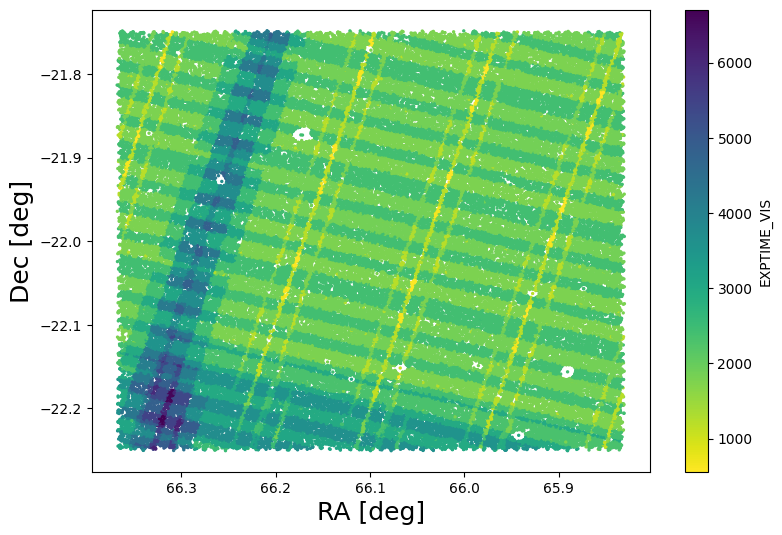

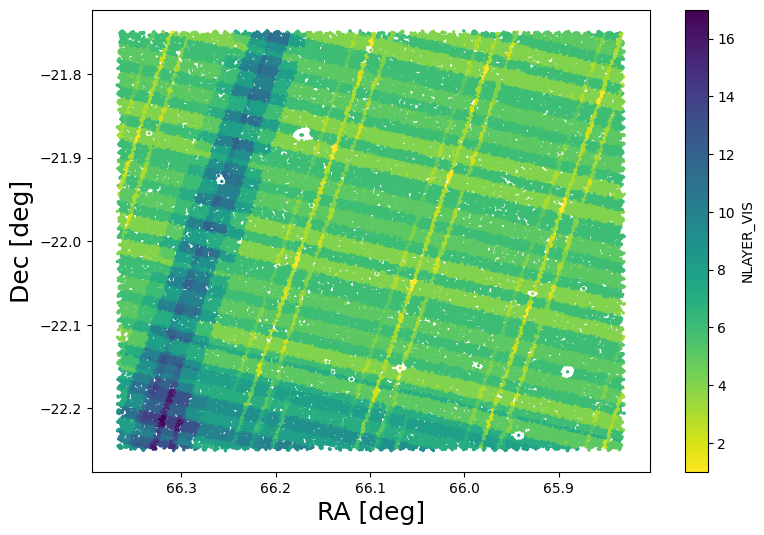

In [10]:
for exp_table in exp_tables:
    logger.info('# Plotting data from able: %s'%exp_table)
    new_cat_data = fits.getdata(exp_table)
    r_cmap=plt.cm.viridis.reversed()
    for one_band in bands:
        fig=plt.figure(figsize=(9,6))
        ax=fig.add_subplot(111)
 
        if one_band.find('NIR') > -1:
            col_suffix = one_band.split("_")[-1]
        else:
            col_suffix = one_band

        plt.scatter(x=new_cat_data['RIGHT_ASCENSION'],
                    y=new_cat_data['DECLINATION'],
                    c=new_cat_data['EXPTIME_%s'%col_suffix],s=2,
                    cmap=r_cmap,zorder=100)
        ax.set_xlabel('RA [deg]',fontsize=18)
        ax.set_ylabel('Dec [deg]',fontsize=18)
        ax.invert_xaxis()
        plt.colorbar(label='EXPTIME_%s'%one_band, orientation="vertical")
        plt.show()
        
        fig=plt.figure(figsize=(9,6))
        ax=fig.add_subplot(111)        
        plt.scatter(x=new_cat_data['RIGHT_ASCENSION'],
                    y=new_cat_data['DECLINATION'],
                    c=new_cat_data['NLAYER_%s'%col_suffix],s=2,
                    cmap=r_cmap,zorder=100)
        ax.set_xlabel('RA [deg]',fontsize=18)
        ax.set_ylabel('Dec [deg]',fontsize=18)
        ax.invert_xaxis()
        plt.colorbar(label='NLAYER_%s'%one_band, orientation="vertical")
        plt.show()